# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [5]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [7]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [8]:
# mostrar las primeras 5 filas de users
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [9]:
# mostrar las primeras 5 filas de usage

**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [10]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [11]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [12]:
# inspección de users con .info()
users.info

<bound method DataFrame.info of       user_id first_name last_name  age      city  \
0       10000     Carlos    Garcia   38  Medellín   
1       10001      Mateo    Torres   53         ?   
2       10002      Sofia   Ramirez   57      CDMX   
3       10003      Mateo   Ramirez   69    Bogotá   
4       10004      Mateo    Torres   63       GDL   
...       ...        ...       ...  ...       ...   
3995    13995        Ana     Lopez   60  Medellín   
3996    13996     Carlos   Ramirez   24  Medellín   
3997    13997        Ana     Lopez   58    Bogotá   
3998    13998    Mariana     Lopez   57    Bogotá   
3999    13999        Ana     Lopez   20    Bogotá   

                           reg_date     plan churn_date  
0     2022-01-01 00:00:00.000000000   Basico        NaN  
1     2022-01-01 06:34:17.914478619   Basico        NaN  
2     2022-01-01 13:08:35.828957239   Basico        NaN  
3     2022-01-01 19:42:53.743435858  Premium        NaN  
4     2022-01-02 02:17:11.657914478   Bas

In [13]:
# inspección de usage con .info()
usage.info

<bound method DataFrame.info of           id  user_id  type                           date  duration  length
0          1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1          2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2          3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3          4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4          5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN
...      ...      ...   ...                            ...       ...     ...
39995  39996    13497  call  2024-06-29 23:33:56.120903022      5.75     NaN
39996  39997    10941  call  2024-06-29 23:40:27.090677266      3.06     NaN
39997  39998    13038  call  2024-06-29 23:46:58.060451510      8.74     NaN
39998  39999    10863  text  2024-06-29 23:53:29.030225754       NaN    43.0
39999  40000    10759  call  2024-06-30 00:00:00.000000000      1.32     NaN

[40000 rows x 6 columns]>

---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [14]:
# cantidad de nulos para users
print(users.isna().sum())

# proporción de valores nulos
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [15]:
# cantidad de nulos para usage


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- El dataset plans no presenta valores nulos, por lo que no requiere tratamiento. En users, la columa City tiene 469 valores faltantes (11.73%) una proporción moderada -que justifica investigar su causa y considerar imputación o categorizarlos como "Desconocido". La columna churn_date presenta 3534 valores nules (88.35%), lo cual parece coherente si la mayoría de los usuarios siguen activos. En usage, la columna date tiene una cantidad mínima de ausencias (0.13%), por lo que no puede imputarse o eliminarse sin impacto relevante. Las columnas duration (55.19%) y lenght(44.74%)presentan una proporción elevada de valores faltantes, por lo que es necesario investigar si los nulos corresponden a tipos de uso donde dichas métricas no aplican antes de decidir una estrategia de tratamiento 
- Indica qué harías: ¿imputar, eliminar, ignorar?
- La columna city presenta un 11.73% de valores nulos, por lo que se recomienda imputarlos como categoria "Desconocido". La columna churn_date tiene un 88.35% de nulos, pero es probable que indiquen usuarios que no han cancelado servicio, por lo que nulos pueden conservarse. En usage, la columna date tiene solo un 0.13% de valores faltantes y los registros afectados pueden eliminarse. Las columnas duration (55.19%) y lenght(44.74) presentan una gran cantidad de nulos; antes de imputar o eliminar, se debe verificar si los nulos corresponden a tipos de actividad donde estas métricas no aplican, ya que podrían tener significado analítico.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [16]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id`contiene identificadores únicos de usuarios con valores entre 10000 y 13999. No se observan valores fuera del rango esperado ni posibles sentinels
- La columna `age` presenta un valor mínimo de -999, lo cual no corresponde a una edad válida y sugiere la presencia de un valor sentinel utilizado para representar información faltante. Se recomienda reemplazar este valor por NaN antes de continuar con el análisis. Los demás valores se encuentran entre 32 y 79 años, dentro de un rango razonable 

In [17]:
# explorar columnas numéricas de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- Las columnas `id` y `user_id` contienen identificadores numéricos utilizados para identificar registros y usuarios. No se espera encontrar sentinels en estas columnas, aunque conviene verificar que no existan valores duplicados o fuera del rango esperado.
- Las columnas duration y lenght deben revisarse para detectar valores negativos,ceros inusuales o valores extremadamente altos. Además, presentan una gran cantidad de valores nulos, por lo que es posible que algunos registros no apliquen para estas métricas

In [18]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']


- La columna `city` contiene ciudades de residencia de los usuarios. Se observan valores nulos, por lo que será necesario decidir si imputarlos o mantenerlos como "Desconocido"
- La columna `plan`contiene el tipo de plan contratado para cada usuario. Se espera encontrar unicamente los planes definidos en el dataset: plans;cualquier valor distinto podría indicar una inconsistencia

In [19]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type`contiene el tipo de actividad registrada en el servicio. Al revisar sus valores únicos, se espera encontrar un número limitado de categorias válidas. No se observan sentinels numéricos evidentes, por lo que cualquier valor inesperado,vacío o mal escrito debería revisarse como posible incosistencia


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En la columna city se encontraron valores nulos, los cuales pueden considerarse datos faltantes que requieren tratamiento.
En la columna plan no se observan sentinels evidentes, pero cualquier valor distinto de los planes definidos en el dataset debe revisarse como posible inconsistencia.
En la columna type únicamente aparecen las categorías text y call, por lo que no se identifican valores inválidos ni sentinels evidentes. 
- ¿Qué acción tomarías?
- En city, reemplazar los valores nulos por una categoría como "Desconocido" o imputarlos utilizando información adicional si está disponible.
En plan, validar que todos los registros coincidan con los planes permitidos; corregir o investigar cualquier valor fuera de catálogo.
En type, mantener los datos sin cambios, pero verificar que no existan valores vacíos, errores de escritura o categorías adicionales inesperadas.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [20]:

# Convertir a fecha la columna `reg_date` de users
import pandas as pd
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [21]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [22]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date` Se observan registros correspondientes a los años 2022, 2023 y 2024, que están dentro del rango esperado. Sin embargo, también aparecen 40 registros con fecha en 2026, un año posterior al límite del dataset (2024), por lo que se consideran fechas fuera de rango y posibles errores de calidad de datos.

In [23]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64

En `date`La columna date contiene únicamente registros del año 2024 (39,950 registros). No se observan años fuera del rango esperado ni fechas futuras, por lo que no se identifican inconsistencias temporales en esta columna.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Sí. En la columna reg_date se encontraron 40 registros correspondientes al año 2026, mientras que los datos del proyecto solo deberían llegar hasta 2024. Estos registros se consideran fechas fuera de rango. Por otro lado, la columna date únicamente contiene registros del año 2024, por lo que no presenta problemas de este tipo.
- ¿Qué harías con ellas?
- Revisar los registros de reg_date con año 2026 para confirmar si se trata de errores de captura.
Si no es posible corregirlos, reemplazarlos por valores nulos (NaT) o excluirlos del análisis.
Mantener los registros de date sin modificaciones, ya que se encuentran dentro del rango esperado.
Documentar cualquier cambio realizado durante el proceso de limpieza de datos.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [24]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [25]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)


Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [26]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [27]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].apply(lambda x: x.isna().sum())


type
call        0
text    22076
Name: duration, dtype: int64

In [28]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].apply(lambda x: x.isna().mean())


type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Los valores nulos en duration y length no parecen ser errores aleatorios, sino que dependen del tipo de actividad registrado en la columna type.
En duration, todos los valores nulos corresponden a registros de tipo text (22,076 nulos), mientras que las llamadas (call) no presentan valores faltantes. Esto es coherente, ya que los mensajes de texto no tienen duración.
En length, aproximadamente el 99.9% de los registros de tipo call presentan valores nulos, mientras que los registros de tipo text no tienen valores faltantes. Esto también es coherente, ya que la longitud del mensaje solo aplica a los mensajes de texto.
Por lo tanto, los valores faltantes están asociados al tipo de actividad y representan una ausencia lógica de información, no un problema de calidad de datos. Se recomienda mantener estos valores como nulos y no imputarlos, para conservar el significado original de los registros y evitar introducir información incorrecta en el análisis.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [29]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:
# Renombrar columnas
usage_agg.columns = [
    'user_id',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [31]:

users_usage = users.merge(usage_agg, on='user_id', how='left')

users_usage.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [32]:
# Resumen estadístico de las columnas numéricas
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,48.136000
std,1154.844867,17.689919
min,10000.000000,18.000000
25%,10999.750000,33.000000
50%,11999.500000,48.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [33]:

# Distribución porcentual del tipo de plan
users['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

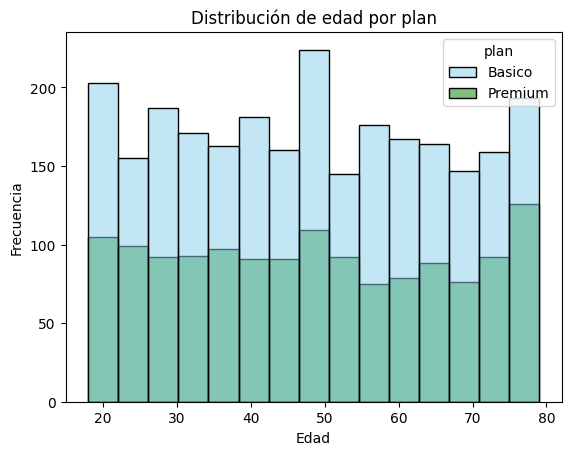

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# Histograma para visualizar la edad (age)
sns.histplot(
    data=users,
    x='age',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15
)

plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución ...

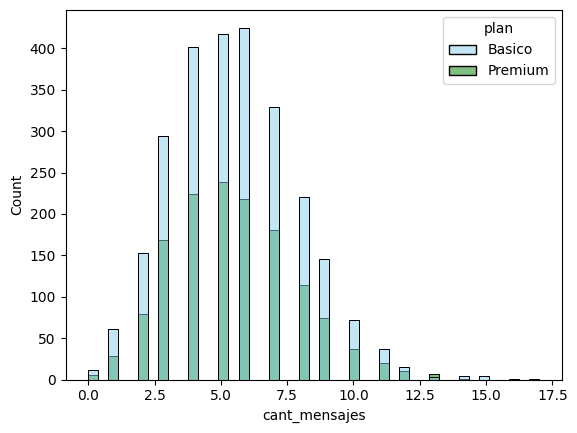

In [35]:
# cant_mensajes
sns.histplot(
    data=users_usage,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.show()


💡Insights: 
La distribución de cant_mensajes es asimétrica con sesgo a la derecha, ya que la mayor parte de los usuarios envía entre 3 y 8 mensajes, mientras que pocos usuarios superan los 10 mensajes. Además, las distribuciones de los planes Básico y Premium son muy similares, por lo que no se observa una diferencia clara en la cantidad de mensajes enviados entre ambos planes.

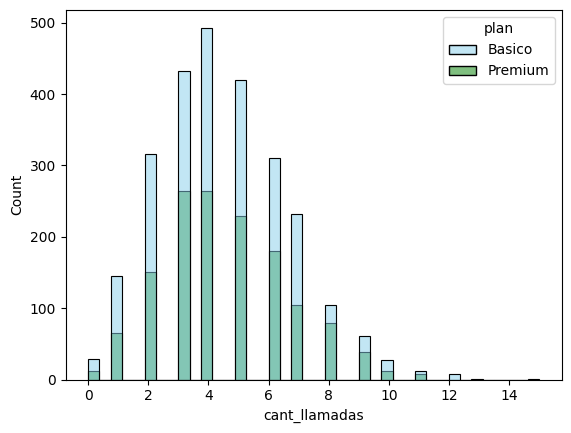

In [36]:
# Histograma para visualizar la cant_llamadas
# cant_llamadas
sns.histplot(
    data=users_usage,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.show()

💡Insights: 
- La distribución de cant_llamadas es asimétrica con sesgo a la derecha, ya que la mayoría de los usuarios realiza entre 3 y 6 llamadas, mientras que pocos usuarios superan las 10 llamadas. Además, las distribuciones de los planes Básico y Premium son muy similares y presentan una alta superposición, por lo que no se observa una diferencia clara en la cantidad de llamadas realizadas según el plan contratado.

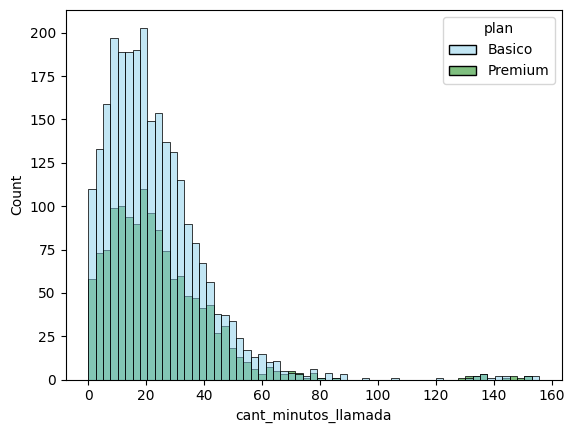

In [37]:
# cant_minutos_llamada o total_minutos_llamada
sns.histplot(
    data=users_usage,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green']
)
plt.show()# Histograma para visualizar la cant_minutos_llamada


💡Insights: 
La variable cant_minutos_llamada presenta una distribución claramente sesgada a la derecha. La mayoría de los usuarios acumula entre 5 y 40 minutos de llamadas, mientras que un grupo reducido alcanza valores mucho más altos, llegando incluso a más de 120 minutos.
Los usuarios de los planes Básico y Premium muestran patrones de uso muy similares, aunque el plan Premium parece tener una presencia ligeramente mayor en los valores más altos de minutos consumidos. Sin embargo, existe una gran superposición entre ambas distribuciones, por lo que no se observa una diferencia contundente entre los planes.
La cola larga hacia la derecha indica la presencia de usuarios intensivos que utilizan significativamente más minutos de llamada que la mayoría de la población, lo que podría influir en métricas como la media.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

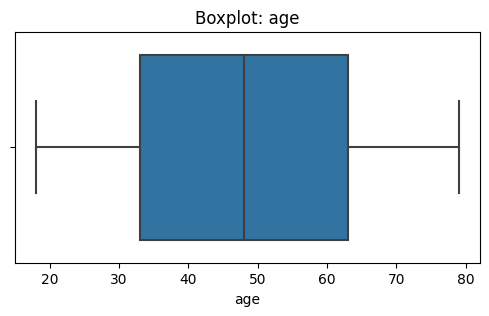

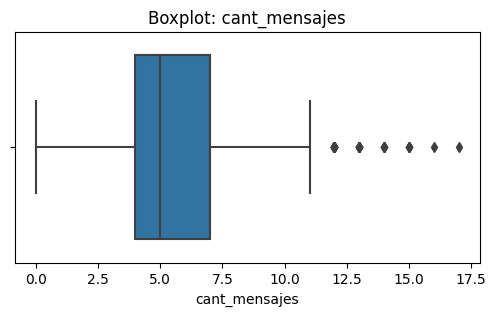

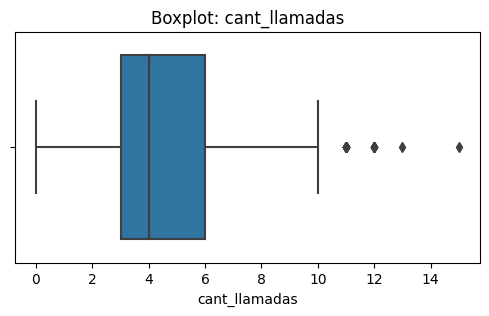

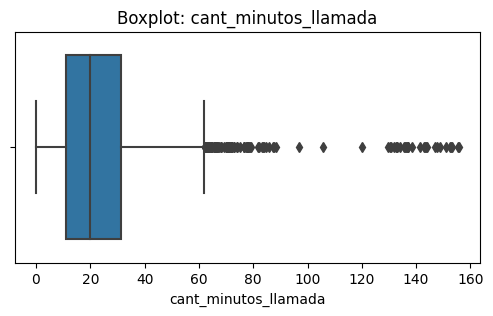

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=users_usage[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

In [40]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = users_usage[col].quantile(0.25)
    q3 = users_usage[col].quantile(0.75)
    iqr = q3 - q1

    limite_superior = q3 + 1.5 * iqr

    print(f'\n{col}')
    print(f'Q1: {q1}')
    print(f'Q3: {q3}')
    print(f'Límite superior: {limite_superior}')
    print(f'Máximo: {users_usage[col].max()}')



cant_mensajes
Q1: 4.0
Q3: 7.0
Límite superior: 11.5
Máximo: 17.0

cant_llamadas
Q1: 3.0
Q3: 6.0
Límite superior: 10.5
Máximo: 15.0

cant_minutos_llamada
Q1: 11.12
Q3: 31.415
Límite superior: 61.8575
Máximo: 155.69


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- cant_mensajes: Sí presenta outliers en el extremo superior. Existen algunos usuarios que envían entre 12 y 17 mensajes, una cantidad superior a la mayoría. Sin embargo, estos valores son plausibles y pueden corresponder a usuarios más activos, por lo que se recomienda mantenerlos.
- cant_llamadas: mantener o no outliers, porqué?
- cant_llamadas: Presenta algunos outliers superiores (alrededor de 11 a 15 llamadas). Estos registros no parecen errores, sino usuarios con una frecuencia de llamadas mayor a la habitual. Se recomienda conservarlos.
- cant_minutos_llamada: mantener o no outliers, porqué?
- cant_minutos_llamada: Presenta una cantidad considerable de outliers en el extremo superior, con usuarios que acumulan más de 60 minutos e incluso hasta 160 minutos. Dado que representan patrones de uso intensivo y no valores imposibles, se recomienda mantenerlos para no perder información relevante.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [42]:
# Crear columna grupo_uso

def clasificar_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

users_usage['grupo_uso'] = users_usage.apply(clasificar_uso, axis=1)

# verificar cambios
users_usage.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [ ]:
# verificar cambios
user_profile.head()

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [43]:
# Crear columna grupo_edad

def clasificar_edad(edad):
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

users_usage['grupo_edad'] = users_usage['age'].apply(clasificar_edad)

In [44]:
user_profile = users_usage.copy()

def clasificar_edad(edad):
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)

user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

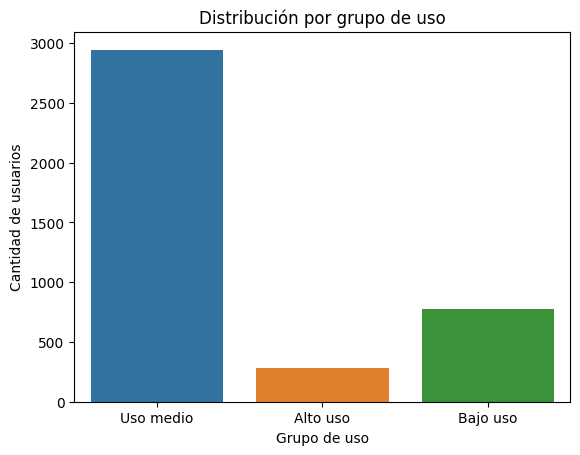

In [45]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Distribución por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

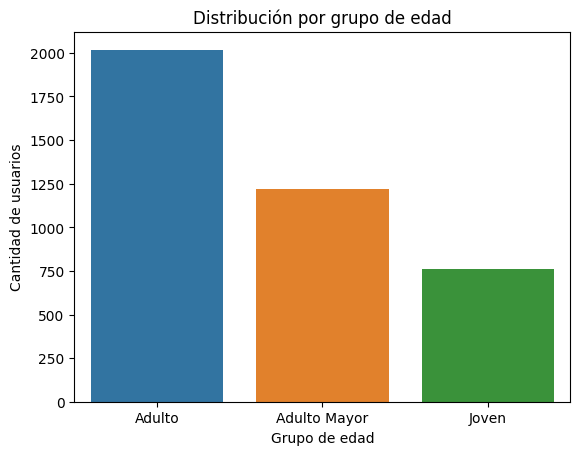

In [46]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
Durante la etapa de limpieza y validación se detectaron varios problemas de calidad:
Se encontraron valores sentinel en la columna age representados por -999, los cuales fueron reemplazados por la mediana de las edades válidas.
Se identificaron valores faltantes o inválidos en city representados por "?", que fueron convertidos a valores nulos.
En reg_date se encontraron 40 registros con fecha en 2026, un año fuera del rango esperado del dataset (hasta 2024), por lo que fueron marcados como valores nulos.
Los valores faltantes en duration y length no correspondían a errores de captura. Se observó que dependían del tipo de actividad (call o text), por lo que representan ausencias lógicas de información y se conservaron.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
A partir de las variables de uso se clasificó a los usuarios en:
Bajo uso: menos de 5 llamadas y menos de 5 mensajes.
Uso medio: menos de 10 llamadas y menos de 10 mensajes.
Alto uso: usuarios con niveles de actividad superiores.
Adicionalmente, se segmentaron por edad:
Joven: menor de 30 años.
Adulto: entre 30 y 59 años.
Adulto Mayor: 60 años o más.
Los histogramas muestran que la mayoría de los usuarios se concentra en niveles de uso moderados, mientras que un grupo reducido presenta una actividad significativamente más intensa. 
-

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?
Los usuarios de alto uso representan el segmento más valioso para la compañía porque:
Consumen más minutos de llamadas.
Generan una utilización más frecuente del servicio.
Son candidatos ideales para planes premium o paquetes adicionales.
Presentan mayores oportunidades de fidelización y venta cruzada.
Los usuarios de uso medio también representan una oportunidad interesante, ya que podrían migrar a planes superiores mediante promociones adecuadas. 
-

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
El análisis mediante boxplots mostró que:
Age: no presenta outliers relevantes.
cant_mensajes: presenta algunos valores extremos superiores.
cant_llamadas: presenta pocos outliers altos.
cant_minutos_llamada: concentra la mayor cantidad de outliers.
Estos valores extremos parecen representar usuarios con patrones de uso intensivo y no errores de captura. Por esta razón se decidió conservarlos, ya que reflejan comportamientos reales del negocio.
Su existencia indica que existe un grupo de clientes altamente comprometidos con el servicio, los cuales podrían requerir ofertas específicas o planes especializados.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
Mantener una estrategia de segmentación basada en uso, diferenciando usuarios de bajo, medio y alto consumo.
Diseñar planes premium para usuarios intensivos, especialmente aquellos con altos minutos de llamada.
Crear campañas de migración para usuarios de uso medio, incentivando la adopción de planes con mayores beneficios.
Desarrollar promociones dirigidas por edad, adaptando los beneficios a las necesidades de cada segmento.
Monitorear continuamente los usuarios de alto consumo, ya que representan una importante fuente de ingresos y pueden anticipar tendencias de comportamiento del mercado.

✍️ **Escribe aquí tu análisis ejecutivo:**
Los datos presentaban algunos problemas de calidad relacionados con valores inválidos, fechas fuera de rango y datos faltantes, los cuales fueron corregidos adecuadamente. Tras la limpieza, se identificó que la mayoría de los usuarios tiene niveles de uso moderados, mientras que existe un grupo reducido de clientes con un consumo significativamente superior. Estos usuarios intensivos constituyen el segmento de mayor valor para ConectaTel y representan una oportunidad para optimizar la oferta comercial mediante planes especializados, estrategias de fidelización y campañas de upselling.

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Se identificaron valores inválidos en la columna age representados por -999, los cuales fueron reemplazados por la mediana para evitar sesgos en el análisis.
Se detectaron valores faltantes en city representados por "?" y 40 registros con fechas en 2026 en reg_date, fuera del rango esperado del dataset. Estos registros fueron corregidos o marcados como nulos para garantizar la calidad de los datos.

🔍 **Segmentos por Edad**
La mayor parte de los clientes pertenece al segmento Adulto (30-59 años), lo que indica que este grupo constituye la base principal de usuarios de ConectaTel.
Los segmentos Joven y Adulto Mayor tienen menor participación, aunque representan oportunidades para diseñar ofertas y campañas específicas según sus necesidades de comunicación.


📊 **Segmentos por Nivel de Uso**
La mayoría de los usuarios se concentra en los grupos de uso bajo y uso medio, realizando cantidades moderadas de llamadas y mensajes.
Existe un grupo reducido de usuarios de alto uso que acumula más llamadas, mensajes y minutos consumidos. Estos usuarios representan una parte importante del consumo total del servicio.

➡️ Esto sugiere que ...
ConectaTel cuenta con una base de clientes relativamente homogénea, pero también con un segmento de usuarios intensivos que puede generar un mayor valor para el negocio y requerir planes especializados.

💡 **Recomendaciones**
Diseñar planes premium o paquetes adicionales dirigidos a usuarios de alto uso, especialmente aquellos con gran consumo de minutos de llamada.
Implementar campañas de migración para usuarios de uso medio, incentivando el cambio a planes con mayores beneficios.
Crear ofertas segmentadas por edad, adaptando promociones y servicios a las características de cada grupo.
Mantener el monitoreo de usuarios intensivos, ya que representan una oportunidad de fidelización y de incremento de ingresos.
Fortalecer los procesos de validación de datos para evitar la aparición de fechas fuera de rango y valores inválidos en futuras cargas de información.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`